In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import argparse
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
import numpy as np
import random
sys.path.append('..')
from models.common_autoencoder_blocks import Encoder  
from models.mnist_supconv import MNISTSupCon
from trainers.supcon_trainer import SupConTrainer
from trainers.classifier_trainer import ClassifierTrainer
from models.mnist_classifier import MNISTClassifier
device = 'cuda' if torch.cuda.is_available() else 'cpu'
class TwoCropsTransform:
    """
    Given one PIL image, apply base_transform twice
    to create two 'views' of the same image.
    """
    def __init__(self, base_transform):
        self.base_transform = base_transform

    def __call__(self, x):
        im1 = self.base_transform(x)
        im2 = self.base_transform(x)
        return im1, im2

base_transform = transforms.Compose([
    transforms.RandomResizedCrop(28, scale=(0.8, 1.0)),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), shear=5),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))], p=0.2),
    transforms.ToTensor(),
])

train_transform = TwoCropsTransform(base_transform)
val_base_transform = transforms.Compose([transforms.ToTensor()])
val_transform = TwoCropsTransform(val_base_transform)
test_transform = TwoCropsTransform(val_base_transform)

In [2]:
#data_path = "/datasets/cv_datasets/data"
data_path = "../data"
full_train_dataset = datasets.MNIST(root=data_path, train=True, download=True)
test_dataset   = datasets.MNIST(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)


train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=2, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=2, drop_last=True)


[Epoch 1] TrainLoss=5.2058, ValLoss=4.4184, TestLoss=4.3584
[Epoch 2] TrainLoss=4.4194, ValLoss=4.2360, TestLoss=4.1940
[Epoch 3] TrainLoss=4.2841, ValLoss=4.1734, TestLoss=4.1390
[Epoch 4] TrainLoss=4.2206, ValLoss=4.1357, TestLoss=4.1014
[Epoch 5] TrainLoss=4.1832, ValLoss=4.1159, TestLoss=4.0819
[Epoch 6] TrainLoss=4.1584, ValLoss=4.0977, TestLoss=4.0673
[Epoch 7] TrainLoss=4.1410, ValLoss=4.0913, TestLoss=4.0620
[Epoch 8] TrainLoss=4.1268, ValLoss=4.0801, TestLoss=4.0549
[Epoch 9] TrainLoss=4.1144, ValLoss=4.0729, TestLoss=4.0472
[Epoch 10] TrainLoss=4.1050, ValLoss=4.0686, TestLoss=4.0398
[Epoch 11] TrainLoss=4.0960, ValLoss=4.0621, TestLoss=4.0370
[Epoch 12] TrainLoss=4.0893, ValLoss=4.0604, TestLoss=4.0347
[Epoch 13] TrainLoss=4.0823, ValLoss=4.0548, TestLoss=4.0311
[Epoch 14] TrainLoss=4.0787, ValLoss=4.0485, TestLoss=4.0278
[Epoch 15] TrainLoss=4.0717, ValLoss=4.0451, TestLoss=4.0253
[Epoch 16] TrainLoss=4.0698, ValLoss=4.0457, TestLoss=4.0270
[Epoch 17] TrainLoss=4.0641, ValL

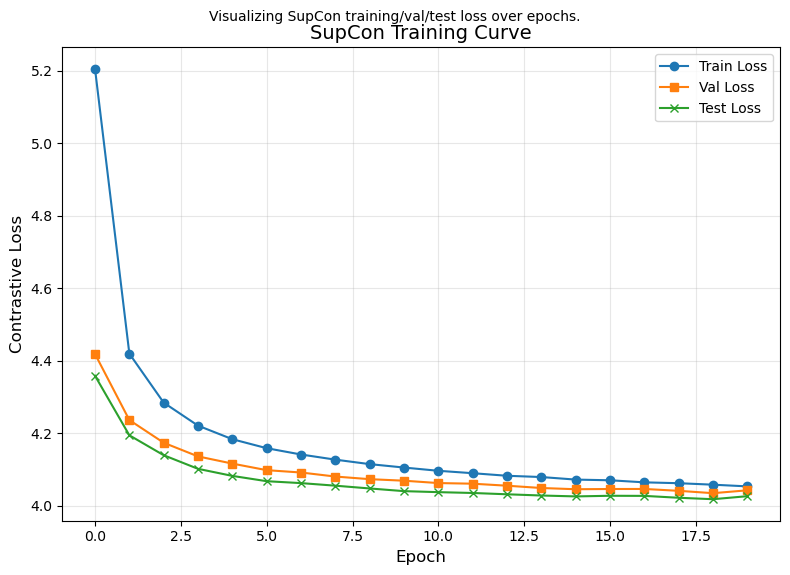

=== Final SupCon Metrics ===
Train Loss: 4.0530
Val   Loss: 4.0421
Test  Loss: 4.0259


In [3]:
supcon = MNISTSupCon(
    input_shape=(1,28,28),
    channels=[32,64],
    kernel_sizes=[3,3],
    strides=[2,2],
    paddings=[1,1],
    latent_dim=128,
    hidden_dims=[1024],
    batch_norm_conv=True
)
optimizer = torch.optim.Adam(supcon.parameters(), lr=1e-4, weight_decay=1e-4)

supcon_trainer = SupConTrainer(
    model=supcon,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader = test_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=20,
    patience=3,
    temperature=0.07
)
supcon_trainer.train()
supcon_trainer.plot_metrics()

In [9]:
classification_train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor()
])
classification_val_transform = transforms.ToTensor()
classification_test_transform = transforms.ToTensor()


full_train_dataset = datasets.MNIST(root=data_path, train=True, download=True)
test_dataset   = datasets.MNIST(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)


train_dataset_classification = TransformedSubset(train_subset, classification_train_transform)
val_dataset_classification = TransformedSubset(val_subset, classification_val_transform)
test_dataset_classification = TransformedSubset(test_dataset, classification_test_transform)
train_classification_loader = DataLoader(train_dataset_classification, batch_size=64, shuffle=True)
val_classification_loader = DataLoader(val_dataset_classification, batch_size=64, shuffle=False)
test_classification_loader = DataLoader(test_dataset_classification, batch_size=64, shuffle=False)

Epoch [1] - TrainAcc: 0.9401, ValAcc: 0.9935, TestAcc: 0.9915 | ValLoss: 0.2226
Epoch [2] - TrainAcc: 0.9867, ValAcc: 0.9940, TestAcc: 0.9916 | ValLoss: 0.0917
Epoch [3] - TrainAcc: 0.9875, ValAcc: 0.9943, TestAcc: 0.9912 | ValLoss: 0.0555
Epoch [4] - TrainAcc: 0.9880, ValAcc: 0.9942, TestAcc: 0.9908 | ValLoss: 0.0429
Epoch [5] - TrainAcc: 0.9881, ValAcc: 0.9941, TestAcc: 0.9912 | ValLoss: 0.0321
Epoch [6] - TrainAcc: 0.9881, ValAcc: 0.9947, TestAcc: 0.9912 | ValLoss: 0.0289
Epoch [7] - TrainAcc: 0.9886, ValAcc: 0.9948, TestAcc: 0.9923 | ValLoss: 0.0251
Epoch [8] - TrainAcc: 0.9891, ValAcc: 0.9941, TestAcc: 0.9912 | ValLoss: 0.0236
Epoch [9] - TrainAcc: 0.9883, ValAcc: 0.9949, TestAcc: 0.9914 | ValLoss: 0.0226
Epoch [10] - TrainAcc: 0.9888, ValAcc: 0.9946, TestAcc: 0.9920 | ValLoss: 0.0215
Epoch [11] - TrainAcc: 0.9889, ValAcc: 0.9942, TestAcc: 0.9920 | ValLoss: 0.0209
Epoch [12] - TrainAcc: 0.9894, ValAcc: 0.9943, TestAcc: 0.9914 | ValLoss: 0.0210
Epoch [13] - TrainAcc: 0.9898, ValAcc

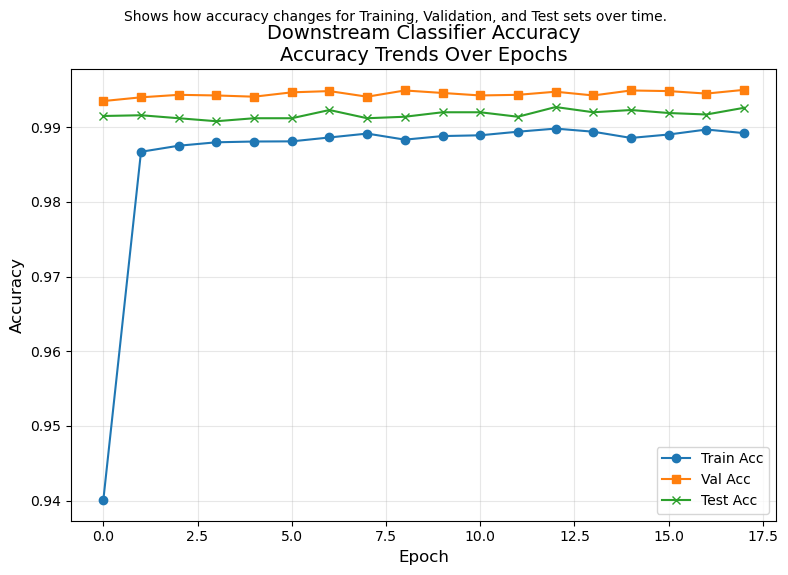

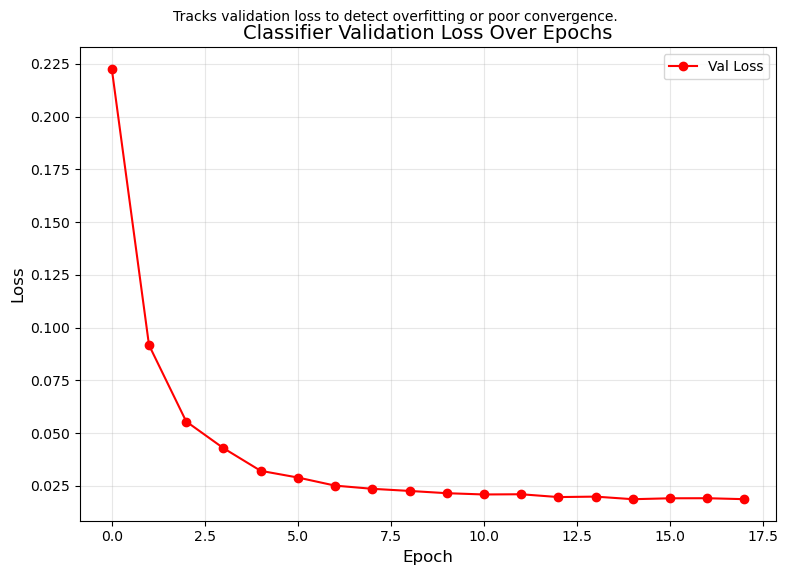

=== Final Classifier Metrics ===
Val Loss: 0.0187
Train Acc: 98.92%
Val   Acc: 99.50%
Test  Acc: 99.26%


In [10]:

classifier = MNISTClassifier(latent_dim=128, num_classes=10, batch_norm_fc=True) 
classifier_trainer = ClassifierTrainer(
    encoder=supcon,
    classifier=classifier,
    train_loader=train_classification_loader,
    val_loader=val_classification_loader,
    test_loader=test_classification_loader,
    device=device,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20,
    patience=3,
)
classifier_trainer.train()
classifier_trainer.plot_metrics()

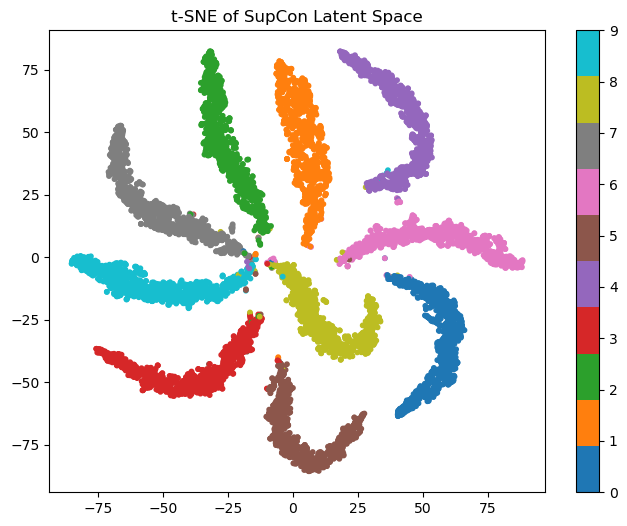

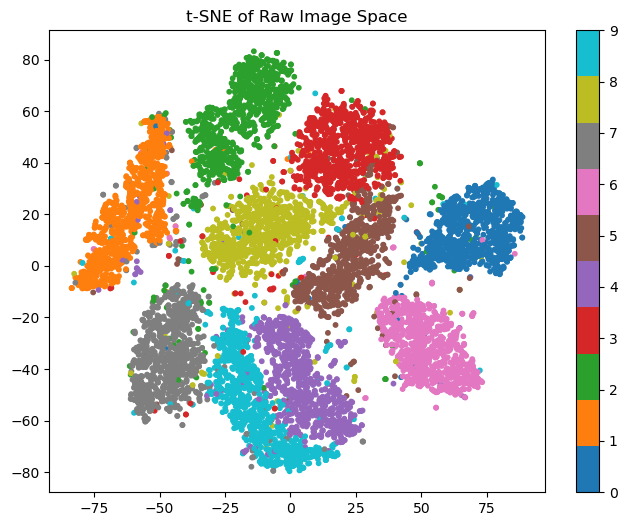

In [11]:
from utils import plot_tsne_supcon
plot_tsne_supcon(supcon, test_classification_loader, device='cuda')
